# PyTorch Through a Numerical Computing Lens
*Cole Spencer · Community Software Analysis*

Pytorch is an industry standard for deeplearning and neural networks, however; under the hood, its a large numerical computing library: 
GPU tensors, automatic differentiation, and linear algebra built on BLAS/LAPACK


## What is PyTorch?
- **Tensors**: n-dimensional arrays (like NumPy) that run on CPU or GPU
- **Autograd**: computes exact derivatives automatically
- **torch.linalg**: QR, SVD, LU solves, which call LAPACK (Apple Accelerate on my Mac)
- **Users**: ML researchers and engineers; underlies tools like Hugging Face

## Metrics (How Fast is defined) 
- **Hardwear Level FLOP/s**: floating-point operations per second
- **ML User Level**: tokens per second
- **Corporate Level**: GPU-hours per training

## Community
- Started 2016 by Meta; now run by the PyTorch Foundation (Linux Foundation)
- ~1,800 contributors last year, ~350 commits/week
- Contributors from Meta, Intel, AMD, NVIDIA, Red Hat, universities
- Contributing needs an `actionable` issue, a signed CLA, and following their AI policy

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.7.0


In [2]:
    def solve_upper_triangular(R, b):
        n = R.shape[0]
        x = torch.zeros_like(b)
        for i in reversed(range(n)):
            x[i] = (b[i] - R[i, i+1:] @ x[i+1:]) / R[i, i]
        return x
    
    A = torch.randn(100, 100, dtype=torch.float64)
    Q, R = torch.linalg.qr(A)
    b = torch.randn(100, dtype=torch.float64)
    
    x_mine  = solve_upper_triangular(R, b)
    x_torch = torch.linalg.solve_triangular(R, b.unsqueeze(1), upper=True).squeeze(1)
    print("Difference:", torch.max(torch.abs(x_mine - x_torch)).item())

Difference: 2.220446049250313e-15


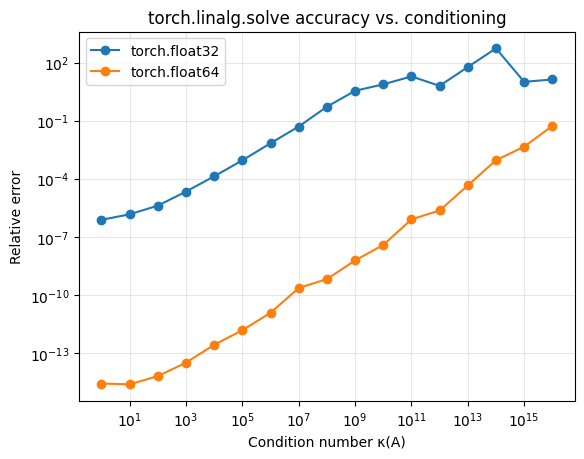

In [3]:
def matrix_with_cond(n, kappa):
    U, _ = torch.linalg.qr(torch.randn(n, n, dtype=torch.float64))
    V, _ = torch.linalg.qr(torch.randn(n, n, dtype=torch.float64))
    s = torch.logspace(0, -np.log10(kappa), n, dtype=torch.float64)
    return U @ torch.diag(s) @ V.T

kappas = 10.0 ** np.arange(0, 17)

for dtype in [torch.float32, torch.float64]:
    errs = []
    for kappa in kappas:
        A = matrix_with_cond(100, kappa)
        x_true = torch.randn(100, 1, dtype=torch.float64)
        b = A @ x_true
        x = torch.linalg.solve(A.to(dtype), b.to(dtype)).double()
        errs.append((torch.linalg.norm(x - x_true) / torch.linalg.norm(x_true)).item())
    plt.loglog(kappas, errs, "o-", label=str(dtype))

plt.xlabel("Condition number κ(A)")
plt.ylabel("Relative error")
plt.title("torch.linalg.solve accuracy vs. conditioning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()